### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd

import sys
sys.path.append("../functions/")
import compare_inter_exp_sim.venturelli2018 as venturelli2018

import compare_inter_exp_sim.correlation as correlation


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
signal_exp = venturelli2018.load_experimental_results()

In [4]:
simulation_dict = venturelli2018.load_simulation_results_pairwise()


## Cooperation and competition - SteadierCom

In [5]:
results_corr_df,results_corr_member_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

steadycom
steadiercom
smetana


In [6]:
results_corr_df_bh = results_corr_df.copy()
results_corr_df_bh["rank"] = results_corr_df_bh["p-value"].rank()
results_corr_df_bh["p-value BH critical"] = (results_corr_df_bh["rank"]/results_corr_df_bh.shape[0])*0.05

results_corr_df_bh["pass BH test"] = results_corr_df_bh["p-value"]<results_corr_df_bh["p-value BH critical"]


In [7]:
results_corr_member_df_bh = results_corr_member_df.copy()
results_corr_member_df_bh["rank"] = results_corr_member_df_bh["p-value"].rank()
results_corr_member_df_bh["p-value BH critical"] = (results_corr_member_df_bh["rank"]/results_corr_member_df_bh.shape[0])*0.05
results_corr_member_df_bh["pass BH test"] = results_corr_member_df_bh["p-value"]<results_corr_member_df_bh["p-value BH critical"]


None of the methods pass the BH test

In [10]:
results_corr_df_bh = results_corr_df_bh.dropna()
results_corr_df_bh.query("`pass BH test`")

,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,,,,,,,


In [11]:
results_corr_df_bh.query("`p-value` < 0.2 & r > 0").xs("coop",drop_level=False).sort_index() # HIGHER THRESHOLD

r  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate  0.209333   
             steadycom         SteadyCom - Fixed abundance            rate?                0.125835   
                               SteadyCom - Nothing fixed              rate?                0.144319   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate  0.021547   
             steadycom         SteadyCom - Fixed abundance            rate?                0.167114   
                               SteadyCom - Nothing fixed              rate?                0.016550   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate        60.0   
             steadycom         SteadyCom - Fixed abundance            rate?                      60.0   
                               SteadyCom - Nothing fixed              rate?                     131.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate            84.0   
             steadycom         SteadyCom - Fixed abundance            rate?                          84.0   
                               SteadyCom - Nothing fixed              rate?                          13.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate   2.0   
             steadycom         SteadyCom - Fixed abundance            rate?                 6.0   
                               SteadyCom - Nothing fixed              rate?                 1.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate             0.006667   
             steadycom         SteadyCom - Fixed abundance            rate?                           0.020000   
                               SteadyCom - Nothing fixed              rate?                           0.003333   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate         False  
             steadycom         SteadyCom - Fixed abundance            rate?                       False  
                               SteadyCom - Nothing fixed              rate?                       False

In [16]:
results_corr_df_bh.query("`p-value` < 0.1 & r < 0").xs("comp",drop_level=False).sort_index()

,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,,,,,,,
comp,smetana,SMETANA,scs,-0.454621,0.060868,12.0,132.0,4.0,0.013333,False


In [17]:
results_corr_df_bh.query("`p-value` < 0.1 & r > 0").xs("coop-comp",drop_level=False).sort_index()

,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,,,,,,,
coop-comp,steadycom,SteadyCom - Nothing fixed,rate?,0.09917,0.098594,132.0,12.0,5.0,0.016667,False


### Member-wise correlation with experimental data
None of the results are significant...

In [18]:
results_corr_member_df_bh = results_corr_member_df_bh.dropna()
results_corr_member_df_bh.query("`pass BH test`")

,,,,,r,p-value,#simulated,#not simulated,rank,p-value BH critical,pass BH test
coop_or_comp,simulation_method,condition,metric,member,,,,,,,


In [20]:
results_corr_member_df_bh.query("`p-value` < 0.1 and r > 0").xs("coop",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH      0.469042   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER      0.489898   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH      0.059853   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER      0.067135   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER            10.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH                 1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER                 2.0   

                                                                                                  rank  \
coop_or_comp simulation_method condition                              metric              member         
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH      15.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER      19.0   

                                                                                                  p-value BH critical  \
coop_or_comp simulation_method condition                              metric              member                        
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH                 0.004167   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER                 0.005278   

                                                                                                  pass BH test  
coop_or_comp simulation_method condition                              metric              member                
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BH             False  
                               SteadierCom - Fixed growth & abundance frequency*mass_rate ER             False

In [22]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r < 0").xs("comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO     -0.563636   
                                                                                          BT     -0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO     -0.563636   
             steadycom         SteadyCom - Nothing fixed              rate?               BO     -0.490909   
                                                                                          BU     -0.672727   
                                                                                          BV     -0.636364   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO      0.016541   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.016541   
             steadycom         SteadyCom - Nothing fixed              rate?               BO      0.040532   
                                                                                          BU      0.003106   
                                                                                          BV      0.005707   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
comp         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            11.0   
             steadycom         SteadyCom - Nothing fixed              rate?               BO            11.0   
                                                                                          BU            11.0   
                                                                                          BV            11.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
comp         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO                 1.0   
                                                                                          BT                 1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO                 1.0   
             steadycom         SteadyCom - Nothing fixed              rate?               BO                 1.0   
                                                                                          BU                 1.0   
                                                                                          BV                 1.0   

                                                                                                  rank  \
coop_or_comp simulation_method condition                              metric              member         
comp         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO       6.0   
                                                                                          BT      12.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO 

In [24]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r > 0").xs("coop-comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO      0.563636   
                                                                                          BT      0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.563636   
             steadycom         SteadyCom - Nothing fixed              rate?               BO      0.527273   
                                                                                          BU      0.563636   
                                                                                          BV      0.636364   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO      0.016541   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.016541   
             steadycom         SteadyCom - Nothing fixed              rate?               BO      0.026384   
                                                                                          BU      0.016541   
                                                                                          BV      0.005707   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            11.0   
             steadycom         SteadyCom - Nothing fixed              rate?               BO            11.0   
                                                                                          BU            11.0   
                                                                                          BV            11.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO                 1.0   
                                                                                          BT                 1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO                 1.0   
             steadycom         SteadyCom - Nothing fixed              rate?               BO                 1.0   
                                                                                          BU                 1.0   
                                                                                          BV                 1.0   

                                                                                                  rank  \
coop_or_comp simulation_method condition                              metric              member         
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency*mass_rate BO       6.0   
                                                                                          BT      12.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO 

#### SteadierCom - scatterplot - frequency*mass_rate

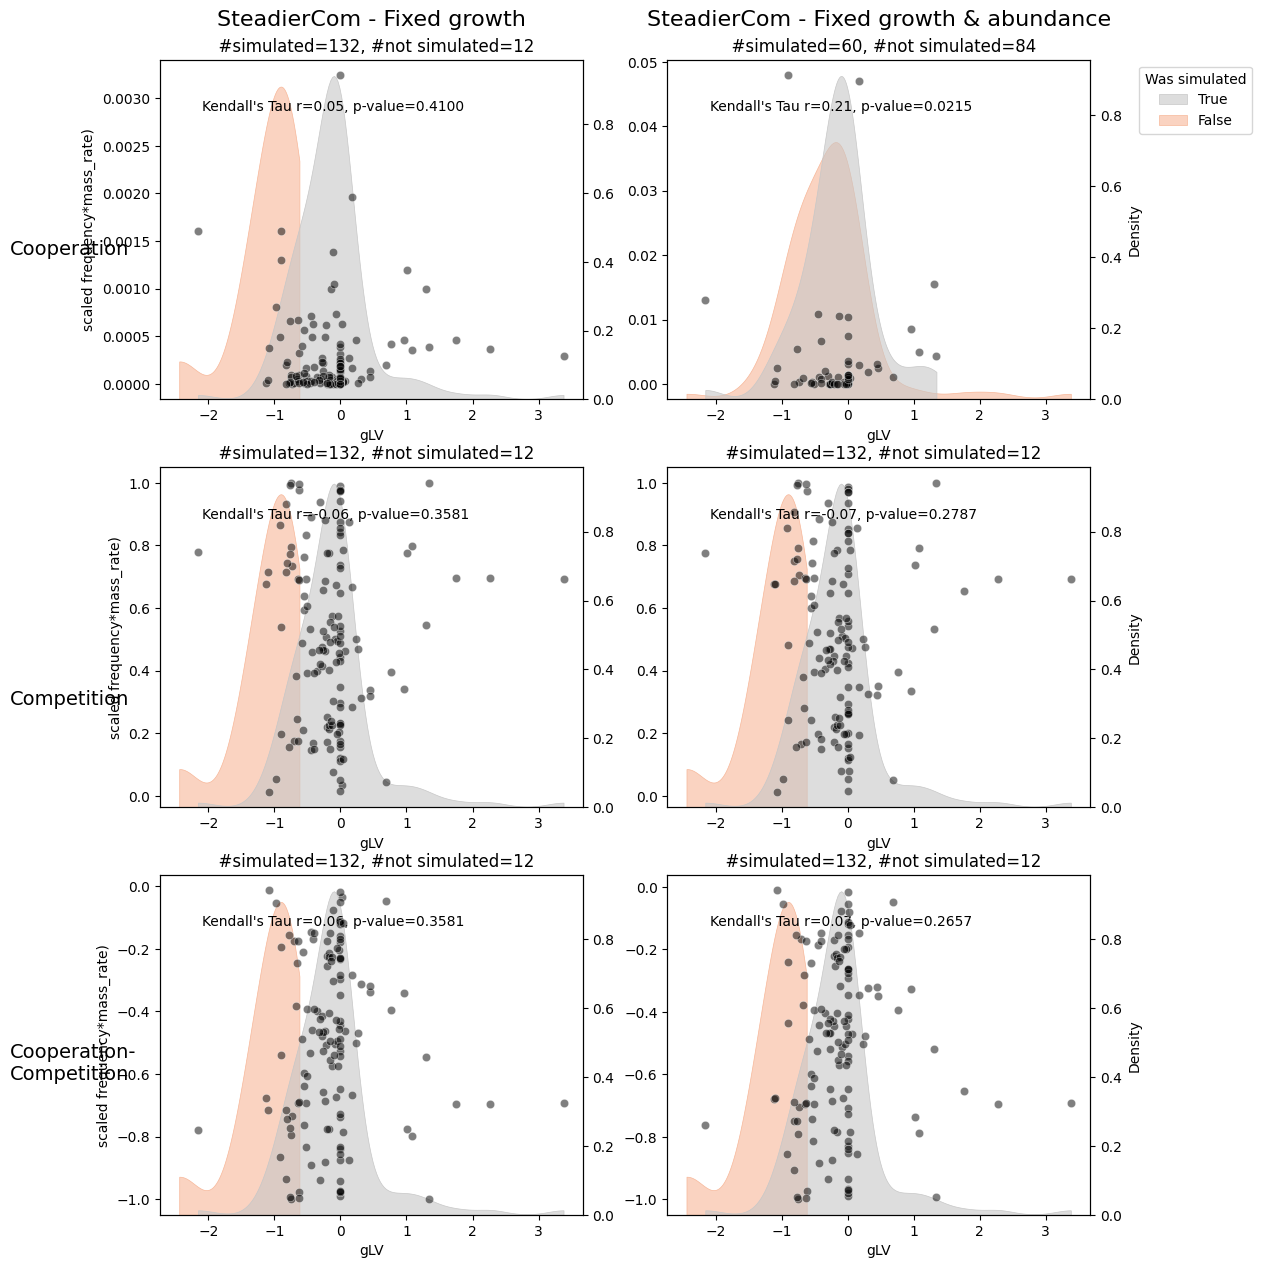

In [25]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency*mass_rate",
                                                                                )

<Axes: xlabel='member_second'>

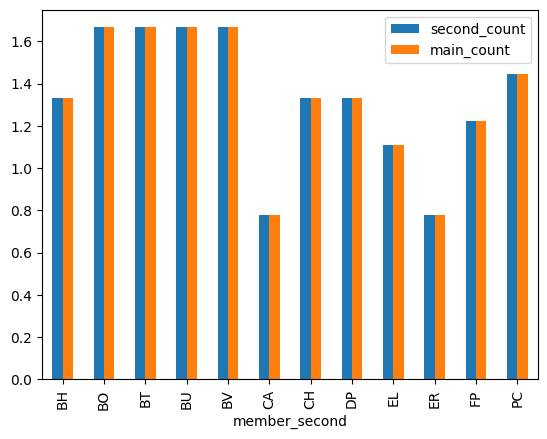

In [27]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")

#### SteadyCom - scatterplot - rate?

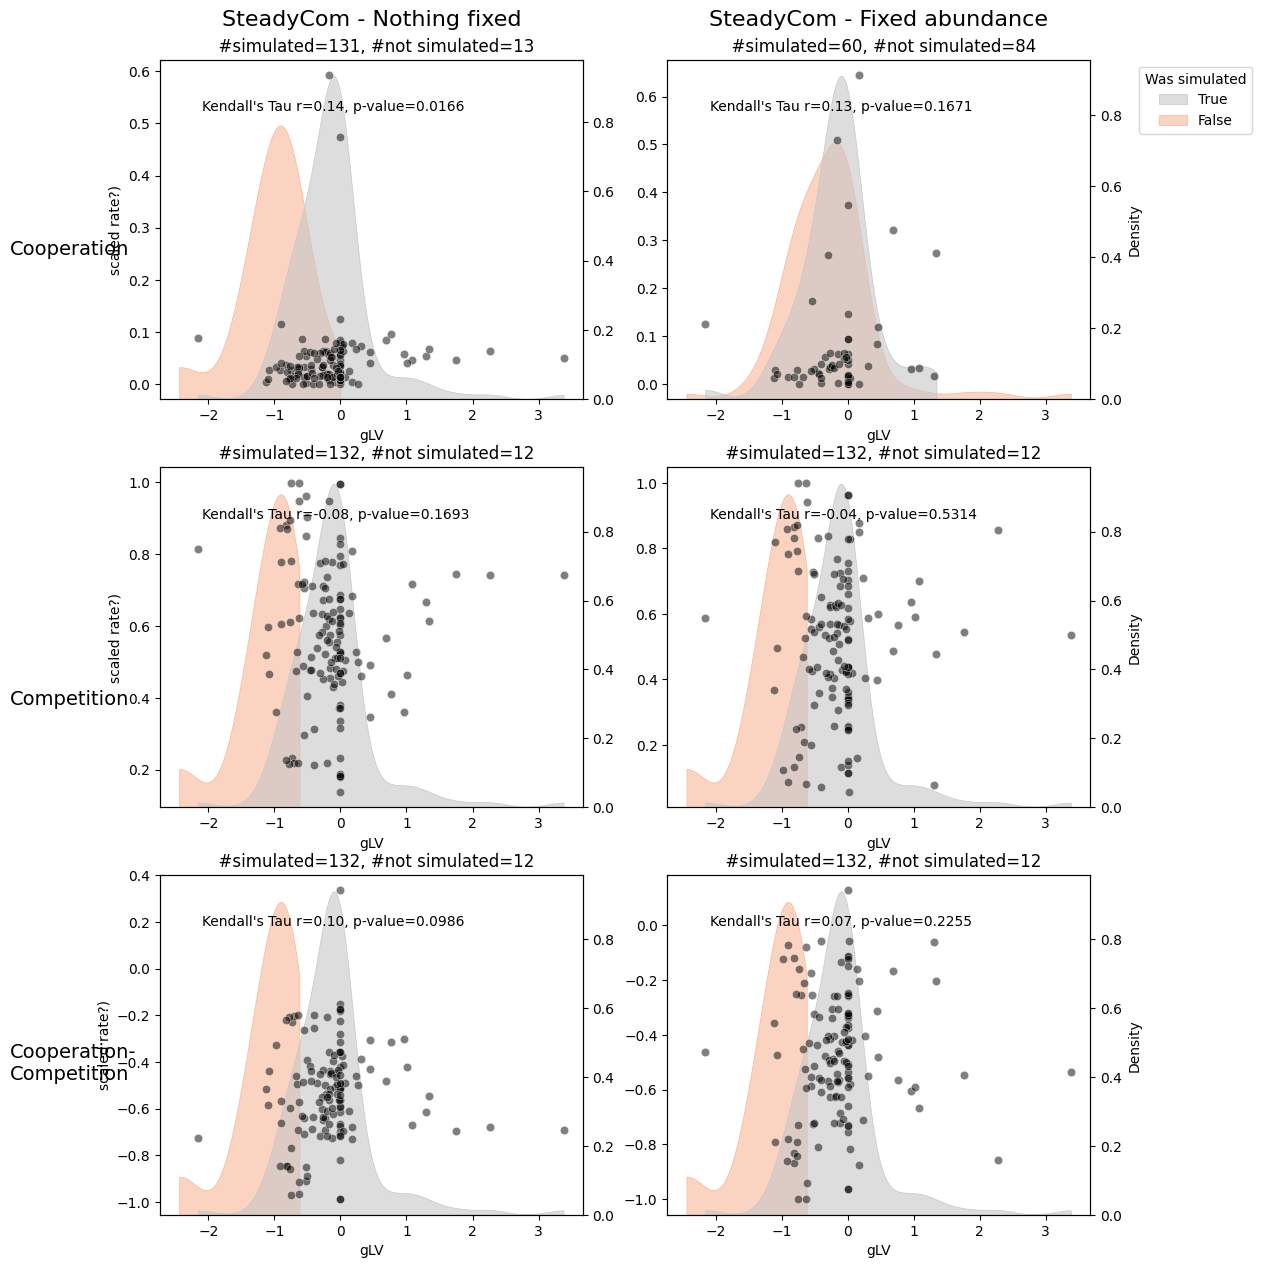

In [28]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadycom",
                                                                                 metric="rate?")

<Axes: xlabel='member_second'>

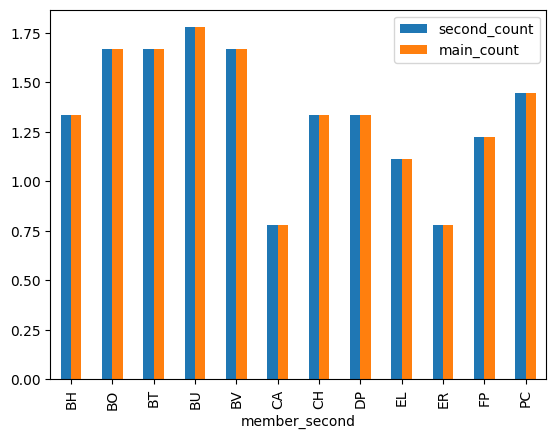

In [29]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")